In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


## Problem

**Objective:** Predict whether a passenger survived the Titanic disaster using passenger characteristics. This is a binary classification problem. The target variable is survived, where 0 represents did not survive and 1 represents surviving.

## 1. Load and inspect the data

In [2]:
#Load Libraries
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = sns.load_dataset("titanic")

# First look
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
print("Original shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

# Inspect some duplicate rows
display(
    df[df.duplicated(keep=False)]
    .sort_values(by=list(df.columns))
    .head(10)
)

Original shape: (891, 15)
Exact duplicate rows: 107


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
734,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
134,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
343,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
666,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


In [5]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

Since some columns give the same info, we can drop one of them
* **class:** another representation of pclass.
* **who and adult_male:** derived from information such as age and sex.
* **embark_town:** overlaps with embarked.
* **deck:** has substantial missingness.
* **alone:** related to family-member counts.

In [6]:
# Since some columns values give the same info, we can drop one of them
df_modified = df.drop(columns = ['class','who', 'adult_male', 'deck', 'embark_town','alive','alone'])

In [7]:
df_modified.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [8]:
print("Shape:", df_modified.shape)

Shape: (891, 8)


In [9]:
df_modified.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [10]:
# Missing values
print(df_modified.isnull().sum().sort_values(ascending=False))

age         177
embarked      2
pclass        0
survived      0
sex           0
sibsp         0
parch         0
fare          0
dtype: int64


In [11]:
# Target distribution
print(df_modified["survived"].value_counts())

# Percentage in each class
print((df_modified["survived"].value_counts(normalize=True) * 100).round(2))

survived
0    549
1    342
Name: count, dtype: int64
survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [12]:
df_modified.duplicated().sum()

np.int64(111)

### What we learned from this section:

**1. How many rows and columns do we have?**\
We have 890 rows and 15 columns.

**2. Which columns contain missing values?**\
These 4 columns contain missing values.
* age            177
* embarked         2

**3. Is the target balanced?** No

**4. Which columns are numeric, categorical, or Boolean?**
* 'survived', 'pclass', 'age', 'sibsp', 'parch', 'fare' are numerical columns.
* 'embarked' is categorical.  

**5. Are any columns duplicates of information you already have?**\
There are 111 duplicate rows. 

## 2. Exploratory Data Analysis (EDA)

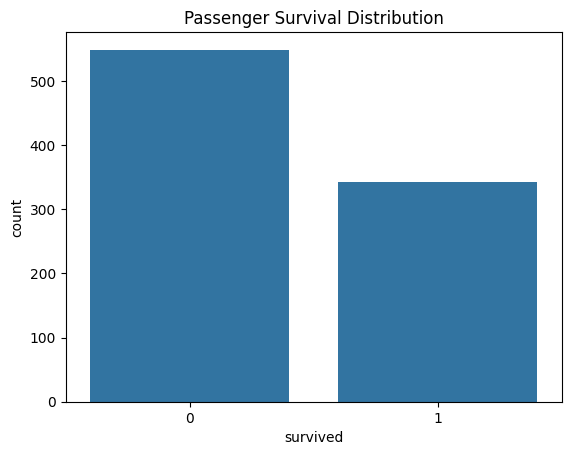

In [13]:
# Overall survival rate
sns.countplot(data = df_modified, x = 'survived')
plt.title("Passenger Survival Distribution")
plt.show()

**How to read it:**
* 0 = Did not survive   
* 1 = Survived   


In this **Passenger Survival Distribution plot**, we can see that more people did not survive than those who did. More people lost their lives than those who survived.

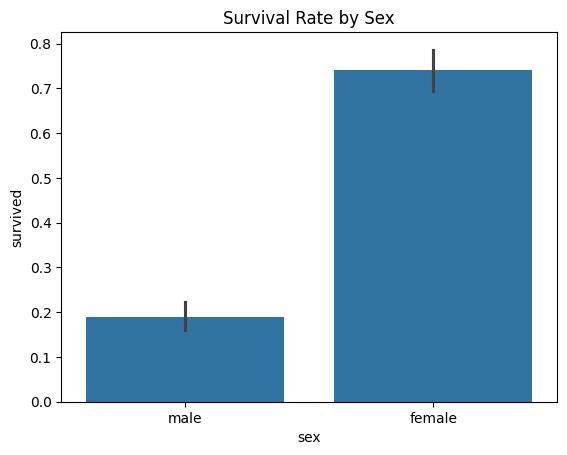

In [14]:
# survival rate by sex
sns.barplot(data = df_modified, x = 'sex', y = 'survived')
plt.title("Survival Rate by Sex")
plt.show()

**How to read it:**
The taller the bar, the higher the chance of survival.

In this **Survival Rate by Sex plot**, the female survival rate is higher than the male survival rate. Gender played a massive role: women had a much higher chance of surviving (around 74%) compared to men (around 20%).

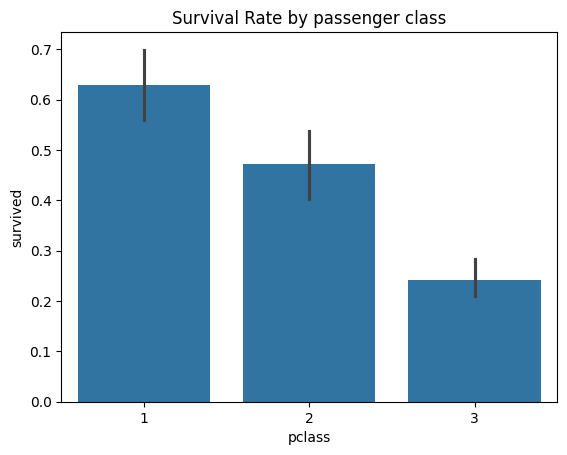

In [15]:
# Survival rate by passenger class
sns.barplot(data = df_modified, x = 'pclass', y = 'survived')
plt.title("Survival Rate by passenger class")
plt.show()

**How to read it:** 
* Class 1 is the highest tier.
* Class 2 is the middle class.
* Class 3 is the lowest.
  
In this **Survival rate by passenger class plot**, Wealthier passengers had a better safety advantage. 1st class passengers have the highest survival rate (around 64%). While the 3rd class passengers have the lowest survival rate (around 22%). 

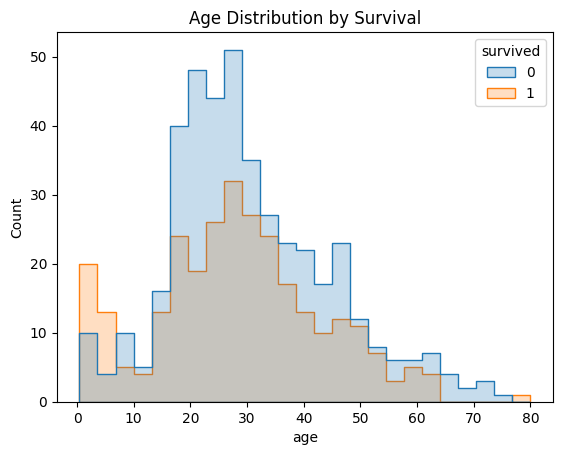

In [16]:
# Age distribution by survival
sns.histplot(
    data=df_modified, x="age", hue="survived",
    bins=25, multiple="layer", element="step"
)
plt.title("Age Distribution by Survival")
plt.show()

In this **Age distribution by survival plot**, notice the very young children (ages 0 to 5) on the far left—the orange bar is taller, meaning young children were heavily prioritized and rescued.

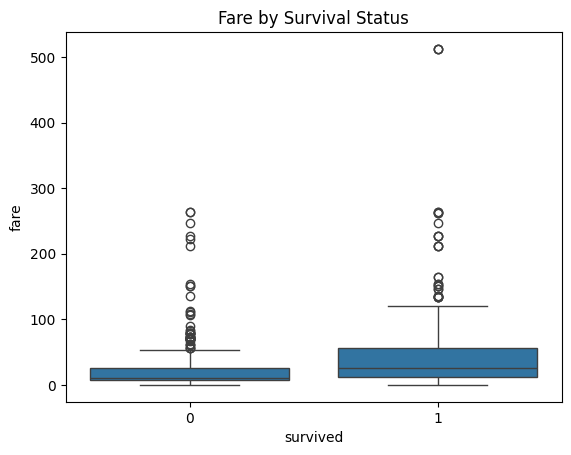

In [17]:
# Fare distribution by survival
sns.boxplot(data=df_modified, x="survived", y="fare")
plt.title("Fare by Survival Status")
plt.show()

**How to read it:** The boxes and dots show the range of ticket prices paid.

In this **Fare by Survival Status plot**, People who paid higher ticket prices generally had a higher chance of survival, matching what we saw with the ticket classes.

## 3. PreProcessing and Pipeline

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [19]:
# Select features and target

X = df_modified.drop(columns="survived")
y = df_modified["survived"]

In [20]:
# Split features and target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [21]:
# 1. Define which columns go where
numeric_features = ['age', 'fare', 'sibsp', 'parch', 'pclass']
categorical_features = ['sex', 'embarked']

In [22]:
# 2. Create a preprocessing sub-pipeline for numerical columns
# It fills missing values (like NaN in age) with the median, then scales
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [23]:
# 3. Create a preprocessing sub-pipeline for categorical columns
# It fills any missing text values (like in 'embarked') with the most frequent category, then encodes
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('cat',OneHotEncoder(drop='first', handle_unknown='ignore'))
])

In [24]:
# 4. Combine both into a ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat',categorical_transformer, categorical_features)
    
])

In [25]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("logreg", LogisticRegression(max_iter=1000))
])

In [26]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare', 'sibsp',
                                                   'parch', 'pclass']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('cat',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('logreg', LogisticRegression(max_iter=1000))])

## 5. Evaluate the model properly

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score
)

In [28]:
# Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

In [29]:
# Logistic Regression predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [30]:
print("Baseline accuracy:", accuracy_score(y_test, baseline_pred))
print("Model accuracy:", accuracy_score(y_test, y_pred))
print("Model ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Model precision:", precision_score(y_test, y_pred))
print("Model recall:", recall_score(y_test, y_pred))
print("Model F1:", f1_score(y_test, y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Baseline accuracy: 0.6145251396648045
Model accuracy: 0.8044692737430168
Model ROC-AUC: 0.8434782608695651
Model precision: 0.7931034482758621
Model recall: 0.6666666666666666
Model F1: 0.7244094488188977

Confusion matrix:
[[98 12]
 [23 46]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



* The model improves accuracy by approximately 18.99 percentage points over the baseline.

* The **baseline** makes the same prediction for every passenger: they did not survive. It gets 110 out of 179 test observations correct.

* The **Logistic Regression** model uses passenger characteristics to distinguish between the two classes. It correctly classifies 144 out of 179 test observations.

**Understand confusion matrix**
* 98 true negatives: The model correctly identified 98 passengers who did not survive.
* 12 false positives: It predicted that 12 passengers survived, but they did not.
* 23 false negatives: It predicted that 23 passengers did not survive, but they actually did.
* 46 true positives: It correctly identified 46 passengers who survived.

**Metric and  results Simple interpretation**
* **Accuracy 80.4%:** 144 of 179 passengers were classified correctly.
* **Precision 79.3%:** Of the 58 passengers predicted to survive, 46 actually survived.
* **Recall 66.7%:** The model identified 46 of the 69 actual survivors.
* **F1-score 72.4%:** A combined measure of precision and recall.
* **ROC-AUC 84.3%:** The model has good ability to rank survivors above non-survivors.

## 6. Evaluating different thresholds

In [31]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_threshold(y_true, y_prob, threshold=0.50):

    # Convert probabilities to class predictions
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold:.2f}")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(precision_score(y_true, y_pred), 3))
    print("Recall:", round(recall_score(y_true, y_pred), 3))
    print("F1:", round(f1_score(y_true, y_pred), 3))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    return y_pred

In [32]:
# Default threshold
y_pred_50 = evaluate_threshold(y_test, y_prob, 0.50)

# Lower threshold
y_pred_35 = evaluate_threshold(y_test, y_prob, 0.35)

# Higher threshold
y_pred_70 = evaluate_threshold(y_test, y_prob, 0.70)


Threshold: 0.50
Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1: 0.724

Confusion Matrix:
[[98 12]
 [23 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Threshold: 0.35
Accuracy: 0.782
Precision: 0.692
Recall: 0.783
F1: 0.735

Confusion Matrix:
[[86 24]
 [15 54]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.78      0.82       110
           1       0.69      0.78      0.73        69

    accuracy                           0.78       179
   macro avg       0.77      0.78      0.77       179
weighted avg       0.79      0.78      0.78       179


Threshold: 0.70
Accuracy: 0.782
Precision: 0.895
Recall: 0.493
F1: 0.636


### Compare thresholds in one table

In [33]:
thresholds = [0.20, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Accuracy,Precision,Recall,F1
0,0.20,0.698,0.574,0.841,0.682
1,0.30,0.760,0.655,0.797,0.719
2,0.35,0.782,0.692,0.783,0.735
3,0.40,0.810,0.740,0.783,0.761
4,0.50,0.804,0.793,0.667,0.724
5,0.60,0.810,0.872,0.594,0.707
6,0.70,0.782,0.895,0.493,0.636
7,0.80,0.721,0.913,0.304,0.457


Three patterns stand out:
- **Lower threshold:** Recall increases, but precision tends to decrease. More passengers are classified as survivors, including more false positives.
- **Higher threshold:** Precision increases, but recall decreases. The model makes fewer positive predictions, so it misses more actual survivors.
- **Threshold 0.40:** In your reported results, it gives the highest F1-score (76.1%) and ties for the highest accuracy (81.0%).

The threshold of 0.40 is therefore a useful candidate to investigate further, not automatically the universally best threshold. The right choice depends on which errors matter most, and a threshold selected using a validation set should be evaluated on your untouched test set.

## 7. Conclusion:
I built a Logistic Regression model to predict Titanic passenger survival using characteristics such as age, sex, passenger class, fare, and family information.

I evaluated the model on a held-out test set of 179 passengers. It correctly classified approximately 80% of them, improving on a simple baseline that always predicted non-survival, which achieved around 61% accuracy.

At the default probability threshold of 0.50, the model correctly identified 46 of the 69 passengers who survived. It also correctly identified 98 of the 110 passengers who did not survive.

The results show that the model can distinguish between the two groups reasonably well, but it still misses some actual survivors. I also experimented with classification thresholds and found that lowering the threshold increased recall while reducing precision.

My next steps would be to interpret the model coefficients, validate the threshold choice, and examine the misclassified cases to understand where the model struggles.

This is a learning project using historical data, so the results demonstrate the modelling workflow rather than a system ready for real-world decisions.

## 8.  Model error analysis

In [34]:
results_df = X_test.copy()

results_df["Actual"] = y_test
results_df["Probability"] = y_prob
results_df["Predicted_50"] = (y_prob >= 0.50).astype(int)
results_df["Predicted_35"] = (y_prob >= 0.35).astype(int)

# Errors at the default threshold
errors_50 = results_df[
    results_df["Actual"] != results_df["Predicted_50"]
]

# Errors at the custom threshold
errors_35 = results_df[
    results_df["Actual"] != results_df["Predicted_35"]
]

print("Errors at threshold 0.50:", len(errors_50))
print("Errors at threshold 0.35:", len(errors_35))

display(
    errors_35[
        ["pclass", "sex", "age", "fare", "Actual",
         "Predicted_35", "Probability"]
    ].head(10)
)

Errors at threshold 0.50: 35
Errors at threshold 0.35: 39


,pclass,sex,age,fare,Actual,Predicted_35,Probability
553,3,male,22.0,7.2250,1,0,0.157489
698,1,male,49.0,110.8833,0,1,0.351583
27,1,male,19.0,263.0000,0,1,0.480878
485,3,female,NaN,25.4667,0,1,0.374481
712,1,male,48.0,52.0000,1,0,0.266890
455,3,male,29.0,7.8958,1,0,0.125101
65,3,male,NaN,15.2458,1,0,0.097554
489,3,male,9.0,15.9000,1,0,0.135120
869,3,male,4.0,11.1333,1,0,0.157876
165,3,male,9.0,20.5250,1,0,0.157769


**Error analysis:** Where is my model getting predictions wrong, and can I learn anything from those mistakes?

**1. Which passengers did the model incorrectly predict would survive?** \
Rows 698, 27,485: the model predicted they survived, but the passengers actually did not survive. 

**2. Which actual survivors did it fail to identify?**\
Rows 554, 712, 455, 65, 489, 869, 165. 

**3. Did changing the threshold correct some errors while creating others?**

### Coefficients: 
What patterns has my model learned from the data, and how does each feature influence its predictions?

In [35]:
# Get the transformed feature names
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get the Logistic Regression coefficients
coefficients = model.named_steps["logreg"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])

display(
    coef_df.sort_values(
        "Coefficient", ascending=False
    ).round(3)
)

,Feature,Coefficient,Odds_Ratio
6,cat__embarked_Q,0.289,1.334
1,num__fare,0.102,1.107
3,num__parch,-0.060,0.942
2,num__sibsp,-0.258,0.773
7,cat__embarked_S,-0.384,0.681
0,num__age,-0.501,0.606
4,num__pclass,-0.916,0.400
5,cat__sex_male,-2.560,0.077
